# 3. Results: do routes of the same size fail on the same photos?

Every model's right/wrong answer is saved for every photo, so models can be compared photo by photo.
- clean photos: all 50,000 ImageNet validation photos
- damaged photos: 14 ImageNet-C damage types at severity 3, on the first 5,000 photos

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import numpy as np
from IPython.display import Image, display

import ast
def show(path, *names):
    """Print the real source of functions/classes from a file in src/ (read directly, never copied)."""
    src = open(path).read(); lines = src.splitlines(); tree = ast.parse(src)
    nodes = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
    for name in names:
        n = nodes[name]; start = n.decorator_list[0].lineno if n.decorator_list else n.lineno
        print(f"# ---- {path}, lines {start}-{n.end_lineno}")
        print("\n".join(lines[start - 1:n.end_lineno])); print()

def show_lines(path, start_text, end_text):
    """Print a block of a script, from the line containing start_text to the line containing end_text."""
    lines = open(path).read().splitlines()
    i = next(k for k, l in enumerate(lines) if start_text in l)
    j = next(k for k, l in enumerate(lines[i + 1:], i + 1) if end_text in l)
    print(f"# ---- {path}, lines {i + 1}-{j + 1}"); print("\n".join(lines[i:j + 1]))

## 3.1 The main table

Built only from measured files (`src/main_table.py`). Accuracy is the mean of 3 seeds, from the re-score that
loaded every model from its file.

In [2]:
import subprocess
print(subprocess.run([sys.executable, "src/main_table.py"], capture_output=True, text=True, check=True).stdout)

Table 1. Four routes at ~9.8 MB vs the uncompressed model (clean: 50,000 images; damaged: mean of 14 corruptions, severity 3, 5,000 images)
model                      file MB  clean %   3-seed range   loss  damaged %  x86 ms  M2 ms
DeiT-S, uncompressed         88.24    79.72                            62.64    71.4   17.8
A  3-bit                     9.718    76.50 [76.44, 76.56]   3.22      55.04    71.4   17.8
B  ternary                   9.785    72.43 [72.26, 72.56]   7.29      44.35    71.4   17.8
C  4-bit + pruning           9.796    75.70 [75.66, 75.73]   4.02      53.55    64.1   16.1
D  distilled DeiT-Tiny       9.765    71.41 [71.24, 71.54]   8.31      48.16    29.9    8.0

Table 2. What each stage buys and costs (seed 0 where a route has seeds)
stage                                                file MB  clean %  damaged %
DeiT-S, 32-bit                                         88.24    79.72      62.64
route A: shrink every weight to 3 bits (group size = weights sharing one

## 3.2 Ruling out luck: the seed floor

Training involves random choices fixed by a **seed**. Two runs of the *same* route with different seeds already
disagree on some photos. That disagreement is the **seed floor**. A difference between routes only counts if two
*different* routes disagree clearly more than that.

Disagreement = share of photos where exactly one of the two models is right.

In [3]:
import itertools
L = {s: json.load(open(f"evidence/logs/evalclean_s{s}.json"))["results"] for s in (0, 1, 2)}
right = lambda r, s: np.array(L[s][r]["clean"]["correct"], dtype=bool)
dis = lambda a, b: (a != b).mean() * 100

floor = {r: np.mean([dis(right(r, a), right(r, b)) for a, b in itertools.combinations((0, 1, 2), 2)]) for r in "ABCD"}
print("seed floor (two runs of the same route disagree on):")
for r in "ABCD": print(f"  route {r}: {floor[r]:.2f}% of 50,000 photos")
print("\n pair   routes disagree   seed floor   ratio")
for x, y in itertools.combinations("ABCD", 2):
    cross = np.mean([dis(right(x, a), right(y, b)) for a in (0, 1, 2) for b in (0, 1, 2) if a != b])
    f = (floor[x] + floor[y]) / 2
    print(f" {x}-{y}  {cross:>12.2f}%  {f:>10.2f}%   {cross/f:.1f}x")

seed floor (two runs of the same route disagree on):
  route A: 8.49% of 50,000 photos
  route B: 9.55% of 50,000 photos
  route C: 7.72% of 50,000 photos
  route D: 6.31% of 50,000 photos

 pair   routes disagree   seed floor   ratio
 A-B         12.31%        9.02%   1.4x
 A-C          9.92%        8.11%   1.2x
 A-D         14.27%        7.40%   1.9x
 B-C         12.38%        8.63%   1.4x
 B-D         14.13%        7.93%   1.8x
 C-D         14.01%        7.02%   2.0x


### The full analysis code

The cell above is a short version. This is the code in `src/offline_analysis.py` that produced the reported
numbers, including 95% confidence ranges from resampling the photos (bootstrap).

In [4]:
show("src/offline_analysis.py", "boot_ci", "mcnemar", "disagree_vec", "jaccard")

# ---- src/offline_analysis.py, lines 65-74
def boot_ci(per_unit, alpha=0.05, B=None):
    """Percentile CI for the MEAN of a per-image quantity, resampling images."""
    B = B or args.boots
    x = np.asarray(per_unit, dtype=np.float64); n = len(x)
    means = np.empty(B)
    for i in range(0, B, 200):                       # chunked: 200 x 50,000 ~ 80 MB of indices
        k = min(200, B - i)
        means[i:i + k] = x[rng.integers(0, n, size=(k, n))].mean(1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(x.mean()), float(lo), float(hi)

# ---- src/offline_analysis.py, lines 76-79
def mcnemar(a, b):
    n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n01, n10, p

# ---- src/offline_analysis.py, lines 89-89
def disagree_vec(a, b): return (a != b).astype(np.float64)

# ---- src/offline_analysis.py, lines 90-92
def jaccard(a, b):
    bw = (~a & ~b).sum(); un 

In [5]:
show_lines("src/offline_analysis.py", "sec1 = {}", "OUT[\"1_seed_vs_route\"]")

# ---- src/offline_analysis.py, lines 94-141
sec1 = {}
for label, getv, n_img in (("clean  (n=50,000)", lambda r, s: v50(r, s), 50000),
                           ("corrupt (n=5,000 x 14)", None, 5000)):
    is_clean = getv is not None
    # per-image disagreement vectors
    def dvec(r1, s1, r2, s2):
        if is_clean:
            return disagree_vec(v50(r1, s1), v50(r2, s2))
        return np.mean([disagree_vec(v5(r1, s1, c), v5(r2, s2, c)) for c in CONDS], axis=0)
    def jac(r1, s1, r2, s2):
        if is_clean:
            return jaccard(v50(r1, s1), v50(r2, s2))
        a = np.concatenate([v5(r1, s1, c) for c in CONDS])
        b = np.concatenate([v5(r2, s2, c) for c in CONDS])
        return jaccard(a, b)

    within = {r: [dvec(r, s1, r, s2) for s1, s2 in itertools.combinations(SEEDS, 2)]
              for r in ROUTES}
    within_j = {r: [jac(r, s1, r, s2) for s1, s2 in itertools.combinations(SEEDS, 2)]
                for r in ROUTES}
    print(f"--- {label}")
    print(f"  

**Reading it:** every pair of routes disagrees 1.2–2.0 times more than two runs of the same route, so routes
of approximately the same size do fail on different photos. (The full analysis in `src/offline_analysis.py`
adds 95% confidence ranges; every range excludes zero.)

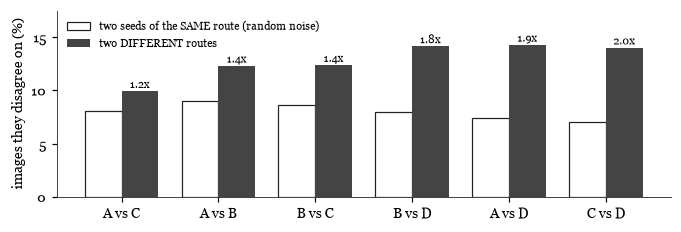

In [6]:
display(Image("proposal/figs/png/fig5_routes_vs_seeds.png", width=700))

## 3.3 Does the clean winner still win on damaged photos?

On clean photos, ternary (B) beats the distilled model (D). On damaged photos, D beats B. Tested per seed:
McNemar's test for clean photos (only photos where exactly one model is right count), and a bootstrap range
for the damaged-photo gap (resample the 5,000 photos 10,000 times).

In [7]:
from scipy.stats import binomtest
R = json.load(open("evidence/rescore/rescore.json"))["results"]
DMG = [k for k in R["A-s0"] if k.endswith("_s3")]
rng = np.random.default_rng(0)
for s in (0, 1, 2):
    b = np.array(R[f"B-s{s}"]["clean"]["correct"]); d = np.array(R[f"D-s{s}"]["clean"]["correct"])
    only_b, only_d = int((b & ~d).sum()), int((~b & d).sum())
    p = binomtest(only_b, only_b + only_d, 0.5).pvalue
    gap = np.mean([np.array(R[f"D-s{s}"][c]["correct"], float) - np.array(R[f"B-s{s}"][c]["correct"], float) for c in DMG], 0)
    boots = [gap[rng.integers(0, 5000, 5000)].mean() for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"seed {s}: clean  B ahead by {100*(b.mean()-d.mean()):+.2f} pts (McNemar p = {p:.1e})"
          f"   |   damaged  D ahead by {100*gap.mean():+.2f} pts, 95% range [{100*lo:+.2f}, {100*hi:+.2f}]")
print("\nstricter bar for 6 tests (Bonferroni): p < 0.05/6 =", round(0.05/6, 4))

seed 0: clean  B ahead by +1.02 pts (McNemar p = 1.2e-09)   |   damaged  D ahead by +3.83 pts, 95% range [+3.34, +4.33]
seed 1: clean  B ahead by +0.92 pts (McNemar p = 3.3e-08)   |   damaged  D ahead by +3.88 pts, 95% range [+3.40, +4.38]


seed 2: clean  B ahead by +1.12 pts (McNemar p = 1.4e-11)   |   damaged  D ahead by +3.71 pts, 95% range [+3.22, +4.20]

stricter bar for 6 tests (Bonferroni): p < 0.05/6 = 0.0083


**Reading it:** the order flips in all three seeds. Route D is a different, smaller network, so this is stated
as a deployment result: a choice made on clean accuracy alone can pick the wrong model.

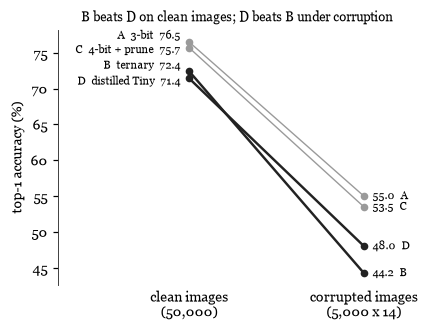

In [8]:
display(Image("proposal/figs/png/fig3_two_rankings.png", width=520))

## 3.4 Which damage hurts which route

Mean accuracy per damage family, averaged over three seeds (archived evaluation).

In [9]:
FAM = {"noise": ["gaussian_noise", "shot_noise", "impulse_noise"], "blur": ["defocus_blur", "motion_blur", "zoom_blur"],
       "weather": ["snow", "frost", "fog", "brightness"], "digital": ["contrast", "elastic_transform", "pixelate", "jpeg_compression"]}
E = {s: json.load(open(f"evidence/logs/eval_s{s}.json"))["results"] for s in (0, 1, 2)}
acc = lambda r, c: np.mean([np.mean(E[s][r][f"{c}_s3"]["correct"]) for s in (0, 1, 2)]) * 100
print(f"{'family':<9}" + "".join(f"{r:>8}" for r in "ABCD"))
for f, cs in FAM.items():
    print(f"{f:<9}" + "".join(f"{np.mean([acc(r, c) for c in cs]):>8.1f}" for r in "ABCD"))

family          A       B       C       D
noise        55.4    36.4    52.9    46.6
blur         45.5    37.5    44.0    39.6
weather      58.3    47.0    57.3    52.7
digital      58.5    52.4    57.2    50.8


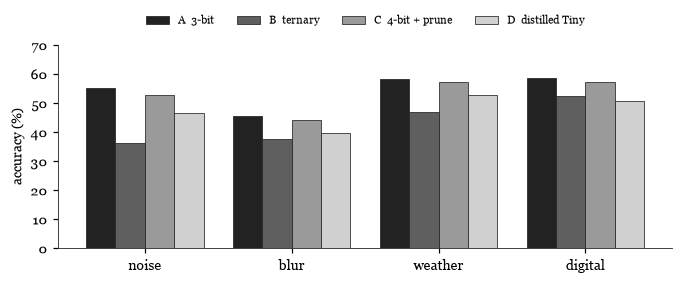

In [10]:
display(Image("proposal/figs/png/fig4_families.png", width=700))